In [1]:
# importing pandas for data analysis and filter warnings to get rid of unnecassary warnings
import pandas as pd
from warnings import filterwarnings
filterwarnings('ignore')

In [2]:
# reading csv and storing it in dataFrame for analysis
df = pd.read_csv('social_ads.csv')

In [3]:
# checking the first 5 columns to get overview of data
df.head()

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0


In [4]:
#checking for the statistical measures of columns
df.describe()

,Age,EstimatedSalary,Purchased
count,400.000000,400.000000,400.000000
mean,37.655000,69742.500000,0.357500
std,10.482877,34096.960282,0.479864
min,18.000000,15000.000000,0.000000
25%,29.750000,43000.000000,0.000000
50%,37.000000,70000.000000,0.000000
75%,46.000000,88000.000000,1.000000
max,60.000000,150000.000000,1.000000


In [5]:
df.shape

(400, 3)

In [6]:
#checking for the null values in each column
df.isnull().sum()

Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [15]:
#checking for the counts of records of each class
df['Purchased'].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

# Data Visulization

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

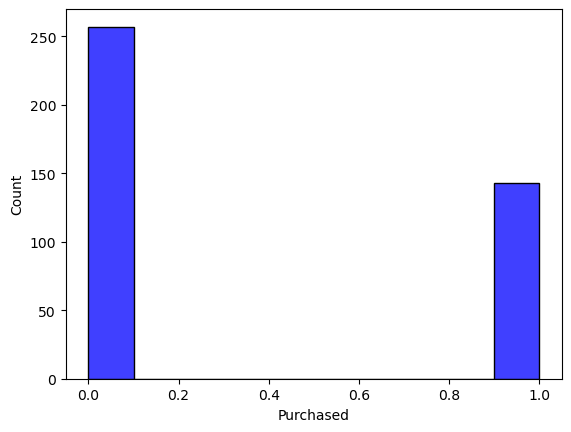

In [17]:
# here we are plotting a histogram to check the value counts of each class
sns.histplot(df['Purchased'],color='b')
plt.show()

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

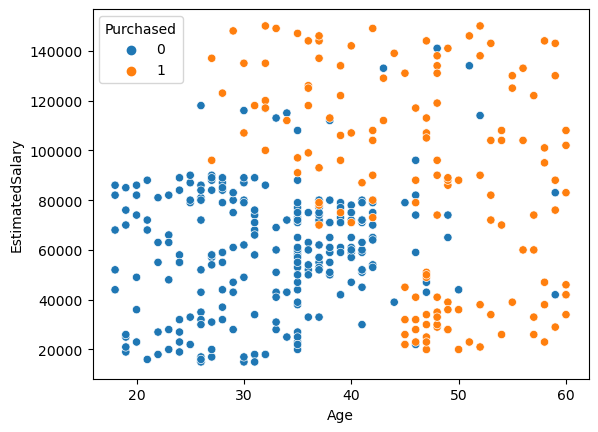

In [18]:
# Plotting a scatter plot to visualize the relationship between 'variance' and 'entropy' columns,  with different colors representing different classes ('class' column)
sns.scatterplot(x=df['Age'],y=df['EstimatedSalary'],hue=df['Purchased'])

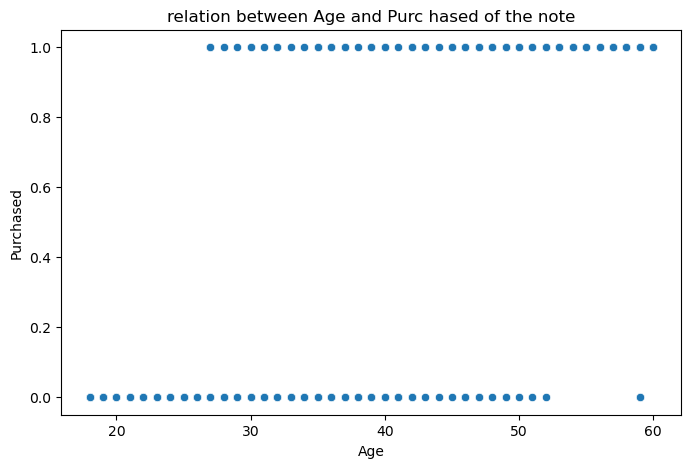

In [19]:
# plotting scatterplot to check the relation between Age  and purchased of the note
plt.figure(figsize=(8,5))
plt.title('relation between Age and Purc hased of the note')
sns.scatterplot(x=df['Age'],y=df['Purchased'])
plt.show()

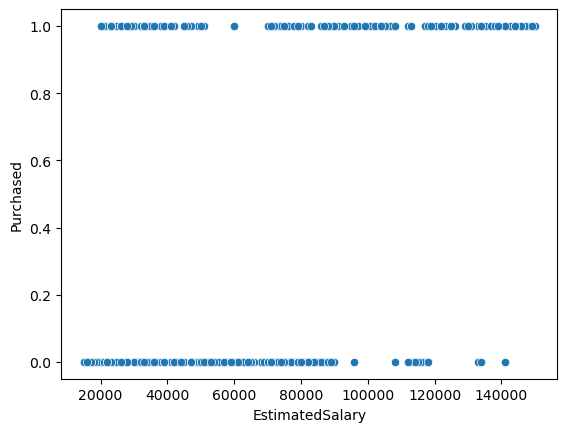

In [20]:
# plotting scatterplot to check the relation between Estimatedsalary and purchased of the note
sns.scatterplot(x=df['EstimatedSalary'],y=df['Purchased'])
plt.show()

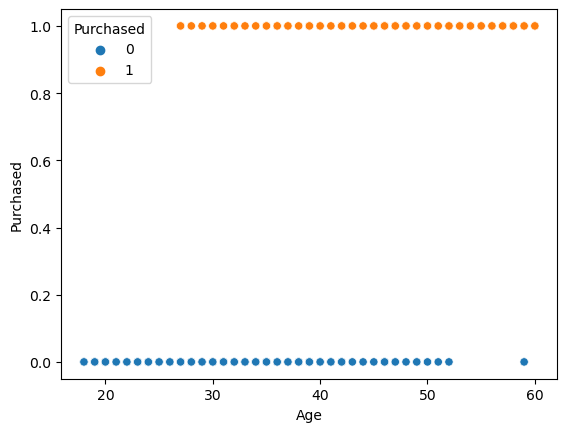

In [22]:
# plotting scatterplot to check the relation between Age and Purchased of the note
sns.scatterplot(x=df['Age'],y=df['Purchased'],hue=df['Purchased'])
plt.show()

In [23]:
df.columns

Index(['Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [24]:
#importing different types of classification models for training and prediction purposes
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import CategoricalNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression

In [25]:
# importing train test split method for splitting the data into training and testing set
from sklearn.model_selection import train_test_split

In [26]:
# separating the label and the features so that we can use them to train and test the models
X = df.drop(['Purchased'],axis=1)
Y = df['Purchased']

In [27]:
# converting the data into trainning and testing set with 20% testing and 80% training data
X_train,X_test,Y_train,Y_test = train_test_split(X,Y,test_size=0.2)

# Logistic Regression

In [28]:
# creating an instance of the Logistic Regression model/class
model = LogisticRegression()

In [29]:
# fitting the model for training purposes and after this the model is trained
model.fit(X_train,Y_train)

LogisticRegression()

In [30]:
#predicting the label using the trained model 
predicted_targets=model.predict(X_test)

In [31]:
# importing the different types of metrices so that we can check the working of our model
from sklearn.metrics import accuracy_score,confusion_matrix,f1_score,recall_score


In [32]:
accuracy_score(y_true=Y_test,y_pred=predicted_targets)

0.625

In [33]:
f1_score(y_true=Y_test,y_pred=predicted_targets)

0.0

In [34]:
recall_score(y_true=Y_test,y_pred=predicted_targets)

0.0

In [35]:
# Calculating and printing the confusion matrix for logistic regression model
logistic_conf_matrix=confusion_matrix(Y_test,predicted_targets)
print(logistic_conf_matrix)

[[50  0]
 [30  0]]


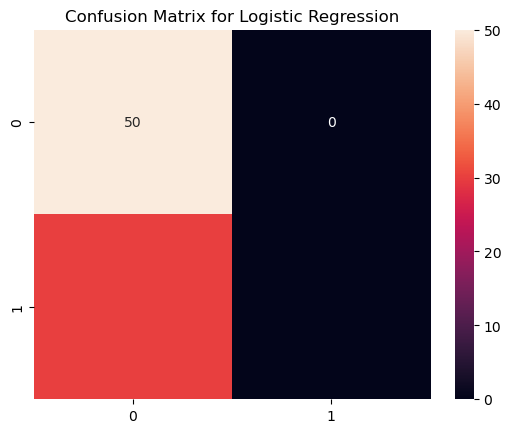

In [36]:
# Displaying the heatmap of the confusion matrix with annotations for each cellplt.title("Confusion Matrix for Logistic Regression")
plt.title("Confusion Matrix for Logistic Regression")
sns.heatmap(logistic_conf_matrix,annot=True)
plt.show()

# K Nearest Neighbour

In [37]:
model = KNeighborsClassifier()

In [38]:
model.fit(X_train,Y_train)

KNeighborsClassifier()

In [39]:
y_pred = model.predict(X_test)

In [40]:
accuracy_score(Y_test,y_pred)

0.7625

In [41]:
f1_score(Y_test,y_pred)

0.6415094339622641

In [42]:
recall_score(Y_test,y_pred)

0.5666666666666667

In [43]:
knn_conf_matrix = confusion_matrix(Y_test,y_pred)
print(knn_conf_matrix)

[[44  6]
 [13 17]]


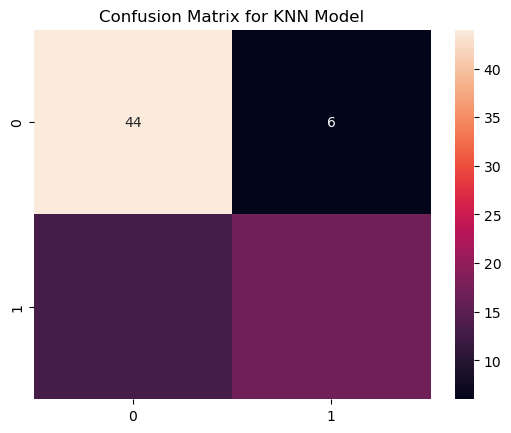

In [44]:
plt.title('Confusion Matrix for KNN Model')
sns.heatmap(knn_conf_matrix,annot=True)
plt.show()